# Predicting Donor Condition from Monocyte Expression

We start with a XGBoost to predict whether a CD14-positive monocyte comes from a
COVID-19 patient or a healthy donor. We want the model to work on unseen donors.

We use the processed, subsampled PBMC dataset from
[Stephenson et al. (2021)](https://pmc.ncbi.nlm.nih.gov/articles/PMC8121667/).
We keep Newcastle samples so we compare both conditions within one site.
Our target is the donor's clinical condition, not whether an individual cell is infected.

# Get the Data

## Import the Required Libraries

In [1]:
from pathlib import Path
import pickle
from importlib.metadata import version

# Dataframes
import pandas as pd

# Arrays and Matrices
import numpy as np

# Single Cell Data
import scanpy as sc

# ML Preprocessing and Modeling
from sklearn.model_selection import (
    train_test_split,
    StratifiedGroupKFold,
    ParameterGrid,
)  # For donor splitting, cross validation and tuning
from sklearn.pipeline import Pipeline  # For combining preparation and prediction
from sklearn.feature_selection import VarianceThreshold  # For removing constant genes
from sklearn.base import clone  # For starting each fold with an unfitted pipeline
from sklearn.utils.class_weight import compute_sample_weight  # For balancing the training classes
from xgboost import XGBClassifier
from sklearn.dummy import DummyClassifier  # For a simple majority-class baseline

# Evaluation
from sklearn.metrics import (
    balanced_accuracy_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

# Visualization
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns

## Load the Data

We have already downloaded the processed `.h5ad` file. It contains expression and cell information
in one AnnData object. The [dataset loader](https://pertpy.scverse.org/en/latest/_modules/pertpy/data/_datasets.html#stephenson_2021_subsampled)
describes the subsampling and provides the download link.

In [2]:
# Set the paths for our data and results
DATA_PATH = Path("stephenson_2021_subsampled.h5ad")
OUTPUT_DIR = Path("outputs/covid_newcastle_xgboost")
# Set the random seed for reproducible splits and model training
RANDOM_STATE = 42
TEST_SIZE = 0.20  # We hold out 20% of the donors

# We load the processed data from our project directory
pbmc = sc.read_h5ad(DATA_PATH)
print(pbmc)
display(pbmc.obs[["patient_id", "Site", "Status", "Swab_result", "cell_type"]].head())

AnnData object with n_obs × n_vars = 62509 × 16299
    obs: 'Collection_Day', 'Swab_result', 'Status', 'Smoker', 'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset', 'Site', 'time_after_LPS', 'Worst_Clinical_Status', 'Outcome', 'patient_id', 'author_cell_type', 'organism', 'sex', 'tissue', 'ethnicity', 'disease', 'assay', 'cell_type', 'dataset_group'
    var: 'gene_id', 'gene_name'
    uns: 'log1p', 'umap'
    obsm: 'X_scVI', 'X_umap'


,patient_id,Site,Status,Swab_result,cell_type
10_1038_s41591_021_01329_2-S11_GAGTCCGGTTCAGGCC-1,AP1,Sanger,Covid,Positive,T follicular helper cell
10_1038_s41591_021_01329_2-S12_ACTGTCCTCTCGTATT-1,AP1,Sanger,Covid,Positive,"central memory CD4-positive, alpha-beta T cell"
10_1038_s41591_021_01329_2-S12_CTCTAATAGTTTCCTT-1,AP1,Sanger,Covid,Positive,"CD16-positive, CD56-dim natural killer cell, h..."
10_1038_s41591_021_01329_2-S12_GCATACAGTAATCGTC-1,AP1,Sanger,Covid,Positive,"naive thymus-derived CD8-positive, alpha-beta ..."
10_1038_s41591_021_01329_2-S12_GACTGCGTCCTTTCGG-1,AP1,Sanger,Covid,Positive,"CD16-positive, CD56-dim natural killer cell, h..."


## Quick Look at the Data

We check the conditions and cell annotations before selecting our cells.

In [3]:
# Show how the conditions are distributed across sites
display(pd.crosstab(pbmc.obs["Site"], pbmc.obs["Status"]))
# Show the most common cell types
display(pbmc.obs["cell_type"].value_counts().head(10).rename("Cells").to_frame())
# Look at how the expression is stored and whether we have raw counts
print("Expression type:", type(pbmc.X).__name__)
print("Available layers:", list(pbmc.layers))
print("Raw expression available:", pbmc.raw is not None)

Expression type: csr_matrix
Available layers: []
Raw expression available: False


Status,Covid,Healthy,LPS
Site,,,
Cambridge,22969,6000,0
Ncl,19818,5790,2636
Sanger,5296,0,0


,Cells
cell_type,
"CD16-positive, CD56-dim natural killer cell, human",8566
CD14-positive monocyte,7986
"central memory CD4-positive, alpha-beta T cell",6564
"naive thymus-derived CD4-positive, alpha-beta T cell",6184
naive B cell,5369
"effector CD8-positive, alpha-beta T cell",4169
"naive thymus-derived CD8-positive, alpha-beta T cell",3597
T-helper 22 cell,2179
T follicular helper cell,1971


# Data Preparation

## Select Newcastle CD14-positive Monocytes

We keep cells annotated as `CD14-positive monocyte`, from Newcastle (`Ncl`), with status
`Covid` or `Healthy`. We exclude LPS-treated samples and other cell types.

This cell annotation includes the authors' `CD14_mono` and `CD83_CD14_mono` groups.
Both map to CD14-positive monocytes in this file. We keep both and exclude CD16 monocytes.
We use clinical status as the target; the cell-type annotation only defines our subset.

In [4]:
# Select CD14-positive monocytes from Newcastle, for our two conditions
selected_cells = (
    (pbmc.obs["Site"] == "Ncl")
    & (pbmc.obs["cell_type"] == "CD14-positive monocyte")
    & pbmc.obs["Status"].isin(["Covid", "Healthy"])
)
# Create an AnnData object with only the selected cells
adata = pbmc[selected_cells].copy()
del pbmc  # We no longer need the full PBMC object

# Give the conditions readable names for our tables and plots
adata.obs["condition"] = (
    adata.obs["Status"].astype(str).map({"Healthy": "Healthy", "Covid": "COVID-19"})
)

# These IDs may refer to repeat samples from the same donor. We group them together,
# because we don't want one sample in training and the other in validation/test.
donor_aliases = {"newcastle21v2": "newcastle21"}
adata.obs["donor_id"] = adata.obs["patient_id"].astype(str).replace(donor_aliases)

# Summarize the cells we are going to use
print(
    f"Selected {adata.n_obs:,} cells, {adata.n_vars:,} genes, and {adata.obs['donor_id'].nunique()} donor groups."
)
display(pd.crosstab(adata.obs["condition"], adata.obs["cell_type"]))
display(pd.crosstab(adata.obs["condition"], adata.obs["Swab_result"]))

Selected 5,934 cells, 16,299 genes, and 54 donor groups.


cell_type,CD14-positive monocyte
condition,
COVID-19,5134
Healthy,800


Swab_result,Healthy,Positive
condition,,
COVID-19,0,5134
Healthy,800,0


## Keep the Existing Expression Preprocessing

This download contains a sparse, normalized and `log1p`-transformed expression matrix in `adata.X`.
It has no raw-count layer. We keep these values, so we don't normalize or log them again.

We check detected genes and non-zero expression, but don't apply raw-count mitochondrial cutoffs
or doublet detection to this processed matrix. We don't use the supplied integrated embeddings.

In [5]:
# Quick look at the expression values and the stored preprocessing information
print(
    "Non-zero expression range:", float(adata.X.data.min()), float(adata.X.data.max())
)
print("log1p metadata:", adata.uns.get("log1p"))

# We undo the log for 100 cells to see whether their expression totals have been normalized.
# This is only for inspecting the data; we still use the original logged values for modeling.
expression_check = adata.X[:100].copy()
expression_check.data = np.expm1(expression_check.data)
normalized_totals = np.asarray(expression_check.sum(axis=1)).ravel()
print(
    "Normalized totals for 100 cells:",
    np.quantile(normalized_totals, [0, 0.5, 1]).round(2),
)
del expression_check

# Count the genes with non-zero expression in each cell. This refers to the genes
# retained in this processed file, so it isn't a count of all genes in the raw data.
adata.obs["n_genes_detected"] = np.asarray((adata.X > 0).sum(axis=1)).ravel()

Non-zero expression range: 0.12473628669977188 6.880120277404785
log1p metadata: {}
Normalized totals for 100 cells: [3351. 3351. 3351.]


## Separate Features, Labels, and Donors

We use genes as features, 0 = healthy and 1 = COVID-19 as labels, and donor IDs for splitting.
Condition, donor ID, clinical severity, and other metadata never enter the feature matrix.
We keep the expression sparse to avoid making a large dense dataframe.

In [6]:
# Split into features (X) and labels (y)
X = adata.X
input_genes = adata.var_names.copy()
# Encode Healthy as 0 and COVID-19 as 1
y = adata.obs["Status"].astype(str).map({"Healthy": 0, "Covid": 1}).astype(int)
# Keep the cell information separately, because we only want genes as model features
obs = adata.obs[
    [
        "donor_id",
        "patient_id",
        "condition",
        "Site",
        "Collection_Day",
        "cell_type",
        "n_genes_detected",
    ]
].copy()

# Create a table with one row per donor, which we will use for the train-test split
donor_table = obs[["donor_id", "condition"]].drop_duplicates().sort_values("donor_id")
display(
    pd.DataFrame(
        {
            "Cells": obs["condition"].value_counts(),
            "Donors": donor_table["condition"].value_counts(),
        }
    )
)

,Cells,Donors
condition,,
COVID-19,5134,42
Healthy,800,12


In [7]:
donor_table

Out[7]: 
                                                          donor_id condition
10_1038_s41591_021_01329_2-CACACAACACCACGTG-MH8...       MH8919176   Healthy
10_1038_s41591_021_01329_2-CTCGTCAGTAGGACAC-MH8...       MH8919177   Healthy
10_1038_s41591_021_01329_2-CTCACACTCTGTCAAG-MH8...       MH8919178   Healthy
10_1038_s41591_021_01329_2-TAAGAGAAGCTTTGGT-MH8...       MH8919179   Healthy
10_1038_s41591_021_01329_2-TAGTGGTCATACTCTT-MH8...       MH8919226   Healthy
10_1038_s41591_021_01329_2-TGAAAGAAGGAATTAC-MH8...       MH8919227   Healthy
10_1038_s41591_021_01329_2-TCAACGATCAGGCGAA-MH8...       MH8919282   Healthy
10_1038_s41591_021_01329_2-CAGTAACAGCTAACAA-MH8...       MH8919283   Healthy
10_1038_s41591_021_01329_2-CGACTTCTCCATGAGT-MH8...       MH8919326  COVID-19
10_1038_s41591_021_01329_2-ATGCGATCATTACGAC-MH8...       MH8919327  COVID-19
10_1038_s41591_021_01329_2-GCGCAGTCAGACGCTC-MH8...       MH8919328  COVID-19
10_1038_s41591_021_01329_2-ACCCACTAGCTAGTCT-MH8...       MH8919329 

## Split into Training and Test Data

We split the donor table, keeping 20% of donors for testing and both conditions in each set.
We then select their cells. All visits and cells assigned to the same donor group stay together.
The fraction of test cells can differ from 20%.

We fix this split before modeling and don't choose another split based on the score.

In [8]:
# Split the donors into train-test, stratified by condition
# We split donors first, because cells from the same person should stay together.
train_donor_table, test_donor_table = train_test_split(
    donor_table,
    test_size=TEST_SIZE,
    stratify=donor_table["condition"],
    random_state=RANDOM_STATE,
)
# Get the donor IDs belonging to each set
train_donors = sorted(train_donor_table["donor_id"].tolist())
test_donors = sorted(test_donor_table["donor_id"].tolist())
# Find the row positions of the cells from those donors
train_idx = np.flatnonzero(obs["donor_id"].isin(train_donors))
test_idx = np.flatnonzero(obs["donor_id"].isin(test_donors))

# Use these positions to split the features, labels and cell information
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_obs, test_obs = obs.iloc[train_idx], obs.iloc[test_idx]

# Show the donor and cell counts in each set
display(
    pd.DataFrame(
        {
            "Training donors": train_donor_table["condition"].value_counts(),
            "Test donors": test_donor_table["condition"].value_counts(),
            "Training cells": train_obs["condition"].value_counts(),
            "Test cells": test_obs["condition"].value_counts(),
        }
    )
)
print("Test donors:", test_donors)

Test donors: ['MH8919282', 'MH8919332', 'MH9143271', 'MH9143274', 'MH9143320', 'MH9143324', 'MH9143326', 'MH9143371', 'MH9143425', 'MH9179824', 'newcastle20']


,Training donors,Test donors,Training cells,Test cells
condition,,,,
COVID-19,33,9,3638,1496
Healthy,10,2,702,98


# Data Exploration

We explore the training set. We check detected genes per cell and sample non-zero expression.
We also check cell numbers per donor because donors contribute different numbers of cells.

,count,mean,std,min,25%,50%,75%,max
condition,,,,,,,,
COVID-19,3638.0,1380.975536,540.291090,444.0,961.00,1298.5,1745.0,3724.0
Healthy,702.0,1548.917379,570.463827,515.0,1089.75,1530.0,1949.0,3555.0


,Cells per training donor
count,43.000000
mean,100.930233
std,57.284750
min,11.000000
25%,58.000000
50%,89.000000
75%,142.500000
max,228.000000


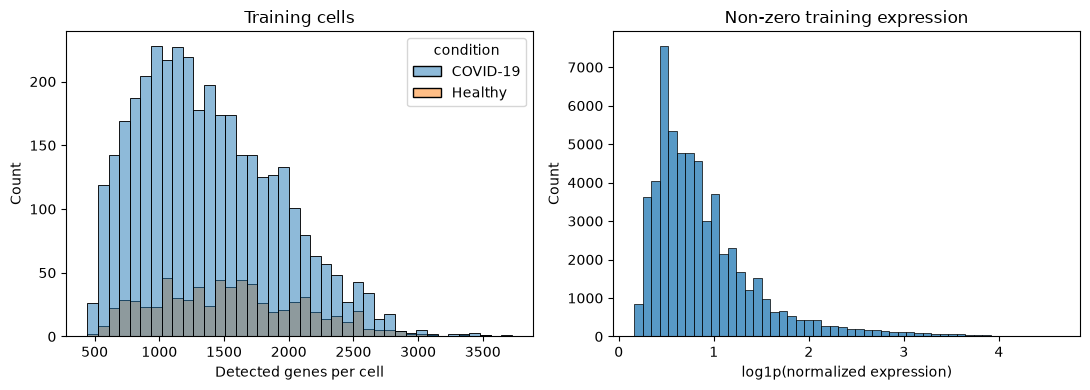

In [9]:
# Summarize detected genes and the number of cells per training donor
display(train_obs.groupby("condition")["n_genes_detected"].describe())
display(
    train_obs.groupby("donor_id")
    .size()
    .describe()
    .rename("Cells per training donor")
    .to_frame()
)

# Create two subplots for the training data
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# Plot the number of detected genes per cell, grouped by condition
sns.histplot(data=train_obs, x="n_genes_detected", hue="condition", bins=40, ax=axes[0])
axes[0].set(xlabel="Detected genes per cell", title="Training cells")

# We take every tenth cell and gene, instead of plotting the whole matrix.
# The sparse matrix's .data contains the non-zero expression values.
sample_expression = X_train[::10, ::10].data
sns.histplot(sample_expression, bins=50, ax=axes[1])
axes[1].set(xlabel="log1p(normalized expression)", title="Non-zero training expression")
plt.tight_layout()
plt.show()

# Modeling

## Prepare the XGBoost Pipeline

XGBoost builds trees sequentially, with each new tree improving the current predictions.
We tune the number of trees, learning rate and tree depth. We use a small grid to start with.

The pipeline removes constant genes and then fits XGBoost. The gene filter is fitted separately
inside each training fold. Validation cells use that fold's fitted filter.
We don't need feature scaling.

We balance the classes using sample weights calculated from each fold's training labels.
Healthy is the smaller class here, so its cells receive more weight.
The validation scores are calculated on the original, unweighted validation cells.

In [10]:
# Create the preparation + prediction pipeline
# When we fit the pipeline, the gene filter is fitted first and XGBoost uses the retained genes.
xgb_pipeline = Pipeline([
    ("constant_genes", VarianceThreshold()),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        importance_type="gain",
        tree_method="hist",  # Use histogram-based splits to keep training reasonably quick
        max_bin=64,
        subsample=0.8,
        colsample_bytree=0.5,
        random_state=RANDOM_STATE,
        n_jobs=4,
    )),
])

## Set Up 5-fold Cross-validation

We divide the training donors into five folds. Each time, we train on four folds and validate on
the remaining fold. Donors stay together, and we try to keep the class proportions similar.
The test donors don't enter CV.

Fold sizes won't be exactly equal because donors contribute different numbers of cells.

In [11]:
# Configure 5-fold cross validation
# We use groups so cells from the same donor stay in the same fold.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_groups = train_obs["donor_id"]

# Generate the folds once, so all parameter combinations are compared on the same splits
cv_splits = list(cv.split(X_train, y_train, groups=train_groups))
# Collect some information about each fold for visualization
fold_rows = []
for fold, (fit_idx, val_idx) in enumerate(cv_splits, start=1):
    # Get the number of training donors and the IDs of the validation donors
    n_fit_donors = train_groups.iloc[fit_idx].nunique()
    val_donors = sorted(train_groups.iloc[val_idx].unique().tolist())

    # Store this fold's donor counts, cell counts and class proportion
    fold_rows.append(
        {
            "Fold": fold,
            "Training cells": len(fit_idx),
            "Validation cells": len(val_idx),
            "Training donors": n_fit_donors,
            "Validation donors": len(val_donors),
            "Validation donor IDs": val_donors,
            "Validation COVID fraction": y_train.iloc[val_idx].mean(),
        }
    )

# Convert the fold information to a dataframe
fold_summary = pd.DataFrame(fold_rows).set_index("Fold")
display(fold_summary.round(3))

,Training cells,Validation cells,Training donors,Validation donors,Validation donor IDs,Validation COVID fraction
Fold,,,,,,
1,3448,892,35,8,"[MH8919226, MH9143272, MH9143327, MH9143420, M...",0.814
2,3490,850,34,9,"[MH8919177, MH8919179, MH8919329, MH8919330, M...",0.860
3,3471,869,35,8,"[MH8919178, MH8919326, MH8919327, MH8919328, M...",0.840
4,3476,864,34,9,"[MH8919283, MH8919331, MH8919333, MH9143270, M...",0.837
5,3475,865,34,9,"[MH8919176, MH8919227, MH9143322, MH9143325, M...",0.842


## Tune the Parameters

We try eight combinations using the same five folds: 40 fits. We choose the parameters with the
highest mean validation balanced accuracy, then train a new pipeline on all training donors.
We also record ROC AUC and average precision.

`n_estimators` controls the number of trees, `learning_rate` controls how much each new tree
contributes, and `max_depth` limits tree depth. Other settings stay fixed for this first search.

We write out the CV loop so we can calculate class weights using only the training labels in each fold.
We give each class the same total training weight, using `n_cells / (2 * n_cells_in_class)` per cell.
We don't use the validation or test labels for those weights.

We tune the number of trees directly and leave early stopping out for now.
The held-out test donors don't enter the search. Nested CV would add outer validation folds
around this tuning procedure, which we can try later.

In [12]:
# Define the hyperparameter options we are going to try
param_grid = {
    "xgb__n_estimators": [100, 200],
    "xgb__learning_rate": [0.05, 0.1],
    "xgb__max_depth": [2, 4],
}

# Store one row per parameter combination and validation fold
cv_rows = []
for candidate, params in enumerate(ParameterGrid(param_grid), start=1):
    for fold, (fit_idx, val_idx) in enumerate(cv_splits, start=1):
        # Split the training data according to this fold
        X_fit, X_val = X_train[fit_idx], X_train[val_idx]
        y_fit, y_val = y_train.iloc[fit_idx], y_train.iloc[val_idx]

        # Calculate class weights using only this fold's training labels
        # Each class has the same total weight, even though it has a different number of cells.
        sample_weights = compute_sample_weight("balanced", y_fit)

        # Create an unfitted pipeline with this parameter combination and fit it
        # clone() makes sure we don't reuse a gene filter or model fitted on another fold.
        fold_model = clone(xgb_pipeline).set_params(**params)
        fold_model.fit(X_fit, y_fit, xgb__sample_weight=sample_weights)

        # Predict on the validation cells using this fold's fitted pipeline
        val_pred = fold_model.predict(X_val)
        val_prob = fold_model.predict_proba(X_val)[:, 1]

        # Compute and store the validation scores
        cv_rows.append({
            "candidate": candidate,
            "Fold": fold,
            **params,
            "balanced_accuracy": balanced_accuracy_score(y_val, val_pred),
            "roc_auc": roc_auc_score(y_val, val_prob),
            "average_precision": average_precision_score(y_val, val_prob),
        })

    print(f"Finished parameter combination {candidate}: {params}")

cv_fold_results = pd.DataFrame(cv_rows)

Finished parameter combination 1: {'xgb__learning_rate': 0.05, 'xgb__max_depth': 2, 'xgb__n_estimators': 100}
Finished parameter combination 2: {'xgb__learning_rate': 0.05, 'xgb__max_depth': 2, 'xgb__n_estimators': 200}
Finished parameter combination 3: {'xgb__learning_rate': 0.05, 'xgb__max_depth': 4, 'xgb__n_estimators': 100}
Finished parameter combination 4: {'xgb__learning_rate': 0.05, 'xgb__max_depth': 4, 'xgb__n_estimators': 200}
Finished parameter combination 5: {'xgb__learning_rate': 0.1, 'xgb__max_depth': 2, 'xgb__n_estimators': 100}
Finished parameter combination 6: {'xgb__learning_rate': 0.1, 'xgb__max_depth': 2, 'xgb__n_estimators': 200}
Finished parameter combination 7: {'xgb__learning_rate': 0.1, 'xgb__max_depth': 4, 'xgb__n_estimators': 100}
Finished parameter combination 8: {'xgb__learning_rate': 0.1, 'xgb__max_depth': 4, 'xgb__n_estimators': 200}


## Check the Cross-validation Results

We compare the parameter combinations and look at each fold for the selected settings.
The standard deviation shows variation across folds; it isn't a confidence interval.

These scores were used to choose the parameters, so the best mean CV score can be optimistic.
We use the held-out donors for the separate evaluation below.

In [13]:
# Summarize the five validation folds for each parameter combination
# We use ddof=0 for the fold SD, as in the previous GridSearchCV results.
cv_results = cv_fold_results.groupby("candidate").agg(
    n_estimators=("xgb__n_estimators", "first"),
    learning_rate=("xgb__learning_rate", "first"),
    max_depth=("xgb__max_depth", "first"),
    mean_balanced_accuracy=("balanced_accuracy", "mean"),
    std_balanced_accuracy=("balanced_accuracy", lambda scores: scores.std(ddof=0)),
    mean_roc_auc=("roc_auc", "mean"),
    mean_average_precision=("average_precision", "mean"),
)
cv_results = cv_results.sort_values("mean_balanced_accuracy", ascending=False, kind="stable")
display(cv_results.round(4))

# Get the individual fold scores and parameters for the best combination
# These are tuning scores, because we used these same folds to choose the parameters.
best_candidate = cv_results.index[0]
best_result = cv_results.loc[best_candidate]
best_params = {
    "xgb__n_estimators": int(best_result["n_estimators"]),
    "xgb__learning_rate": float(best_result["learning_rate"]),
    "xgb__max_depth": int(best_result["max_depth"]),
}
best_fold_scores = cv_fold_results[cv_fold_results["candidate"] == best_candidate].set_index("Fold")
cv_fold_metrics = fold_summary.join(best_fold_scores[["balanced_accuracy", "roc_auc", "average_precision"]])
display(cv_fold_metrics.round(4))
print("Best parameters:", best_params)
print(
    f"Selected settings: mean CV balanced accuracy = {best_result['mean_balanced_accuracy']:.4f}, "
    f"fold SD = {best_result['std_balanced_accuracy']:.4f}"
)

# Train the selected pipeline on the whole training set
# We recalculate the class weights from all training labels for this final fit.
training_weights = compute_sample_weight("balanced", y_train)
model = clone(xgb_pipeline).set_params(**best_params)
model.fit(X_train, y_train, xgb__sample_weight=training_weights)
selected_genes = input_genes[model.named_steps["constant_genes"].get_support()]
print(f"Retained {len(selected_genes):,} of {X_train.shape[1]:,} genes.")

Best parameters: {'xgb__n_estimators': 200, 'xgb__learning_rate': 0.1, 'xgb__max_depth': 2}
Selected settings: mean CV balanced accuracy = 0.9266, fold SD = 0.0471
Retained 13,568 of 16,299 genes.


,n_estimators,learning_rate,max_depth,mean_balanced_accuracy,std_balanced_accuracy,mean_roc_auc,mean_average_precision
candidate,,,,,,,
6,200,0.10,2,0.9266,0.0471,0.9939,0.9988
8,200,0.10,4,0.9239,0.0582,0.9939,0.9988
5,100,0.10,2,0.9227,0.0393,0.9925,0.9985
2,200,0.05,2,0.9218,0.0422,0.9931,0.9986
4,200,0.05,4,0.9170,0.0549,0.9929,0.9986
7,100,0.10,4,0.9149,0.0604,0.9931,0.9986
1,100,0.05,2,0.9145,0.0379,0.9878,0.9976
3,100,0.05,4,0.9095,0.0558,0.9899,0.9980


,Training cells,Validation cells,Training donors,Validation donors,Validation donor IDs,Validation COVID fraction,balanced_accuracy,roc_auc,average_precision
Fold,,,,,,,,,
1,3448,892,35,8,"[MH8919226, MH9143272, MH9143327, MH9143420, M...",0.8139,0.9510,0.9934,0.9985
2,3490,850,34,9,"[MH8919177, MH8919179, MH8919329, MH8919330, M...",0.8600,0.9696,0.9967,0.9995
3,3471,869,35,8,"[MH8919178, MH8919326, MH8919327, MH8919328, M...",0.8400,0.9484,0.9969,0.9994
4,3476,864,34,9,"[MH8919283, MH8919331, MH8919333, MH9143270, M...",0.8368,0.8362,0.9897,0.9980
5,3475,865,34,9,"[MH8919176, MH8919227, MH9143322, MH9143325, M...",0.8416,0.9279,0.9927,0.9986


# Evaluation

## Predict on the Held-out Donors

We use the model's default decision threshold (0.5). COVID-19 is the positive class.
We also fit a majority-class baseline on the training labels for a simple comparison.
XGBoost's settings are chosen using CV scores only.

We have already inspected this holdout while developing the random forest notebook.
We keep the same split, but treat this as an exploratory class-project evaluation.

In [14]:
# Predict on the held-out test cells
# predict() first applies the fitted gene filter and then calls the XGBoost.
y_pred = model.predict(X_test)
# Get the probabilities for the positive class (COVID-19 = 1)
covid_column = np.flatnonzero(model.classes_ == 1)[0]
y_prob = model.predict_proba(X_test)[:, covid_column]

# Train a simple baseline that always predicts the most common training class
# We compare against this to see what XGBoost adds.
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
# Predict on the same test cells with the baseline
baseline_pred = baseline.predict(X_test)
baseline_prob = baseline.predict_proba(X_test)[
    :, np.flatnonzero(baseline.classes_ == 1)[0]
]

## Compare the Scores

Balanced accuracy gives both conditions equal weight. Precision tells us how often a predicted
COVID-19 cell came from a COVID-19 donor; recall tells us how many cells from those donors we find.
ROC AUC and average precision use predicted probabilities, not predicted labels.

These are cell-level scores on unseen donors. Cells from the same donor aren't independent,
and donors with more cells contribute more to the pooled scores. We inspect each donor below.

COVID-19 is the majority class here. We read COVID F1 and average precision alongside the majority
baseline and healthy-cell recall, because high scores on the majority class can hide control errors.

In [15]:
def compute_metrics(y_true, y_pred, y_prob):
    """Compute binary metrics, with COVID-19 donor condition as the positive class."""
    return {
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "COVID precision": precision_score(y_true, y_pred, zero_division=0),
        "COVID recall": recall_score(y_true, y_pred, zero_division=0),
        "COVID F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_true, y_prob),
        "Average precision": average_precision_score(y_true, y_prob),
    }


# Compute the metrics for both models and put them in a dataframe
metrics = pd.DataFrame(
    {
        "Majority baseline": compute_metrics(y_test, baseline_pred, baseline_prob),
        "XGBoost": compute_metrics(y_test, y_pred, y_prob),
    }
)
display(metrics.round(4))
# Show precision, recall and F1 separately for each class
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Healthy", "COVID-19"],
        digits=3,
        zero_division=0,
    )
)

              precision    recall  f1-score   support

     Healthy      0.493     0.755     0.597        98
    COVID-19      0.983     0.949     0.966      1496

    accuracy                          0.937      1594
   macro avg      0.738     0.852     0.781      1594
weighted avg      0.953     0.937     0.943      1594



,Majority baseline,XGBoost
Balanced accuracy,0.5000,0.8521
MCC,0.0000,0.5794
COVID precision,0.9385,0.9834
COVID recall,1.0000,0.9492
COVID F1,0.9683,0.9660
ROC AUC,0.5000,0.9592
Average precision,0.9385,0.9971


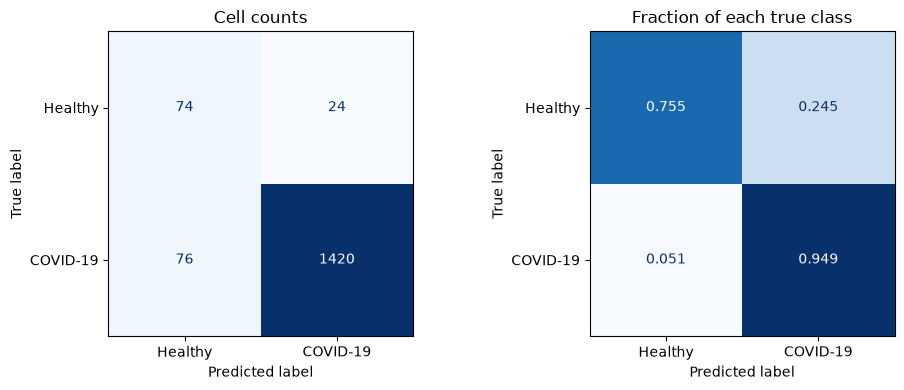

In [16]:
# Plot the confusion matrix as cell counts and as fractions of each true class
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, normalize, title in zip(
    axes, [None, "true"], ["Cell counts", "Fraction of each true class"]
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["Healthy", "COVID-19"],
        normalize=normalize,
        cmap="Blues",
        colorbar=False,
        ax=ax,
        values_format="d" if normalize is None else ".3f",
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

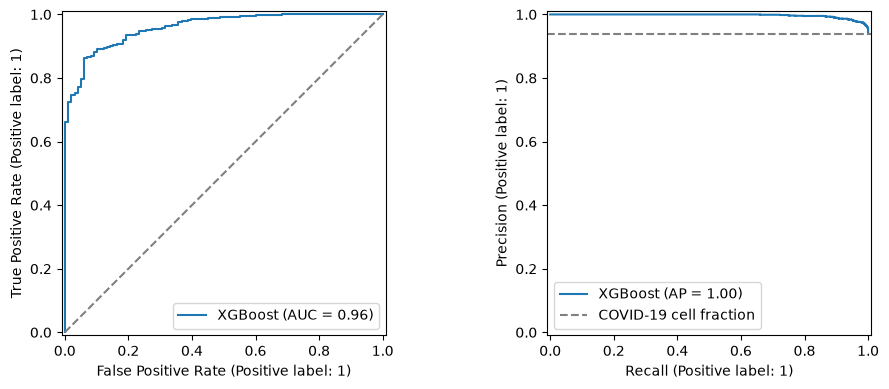

In [17]:
# Create two subplots for the ROC and precision-recall curves
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
RocCurveDisplay.from_predictions(y_test, y_prob, name="XGBoost", ax=axes[0])
# Add the diagonal reference line to the ROC plot
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
PrecisionRecallDisplay.from_predictions(
    y_test, y_prob, name="XGBoost", ax=axes[1]
)
# Add the positive-class fraction as a reference for average precision
axes[1].axhline(
    y_test.mean(), linestyle="--", color="gray", label="COVID-19 cell fraction"
)
axes[1].legend()
plt.tight_layout()
plt.show()

## Check Each Test Donor

Each donor has one condition, so per-donor ROC AUC and balanced accuracy would be inappropriate.
We show cell counts, the fraction of cells correctly classified, and mean predicted COVID probability.
The probabilities aren't calibrated confidence estimates.

In [18]:
# Combine the cell information, reference labels and predictions
test_predictions = test_obs.copy()
test_predictions["true_label"] = y_test
test_predictions["predicted_label"] = y_pred
test_predictions["predicted_condition"] = test_predictions["predicted_label"].map(
    {0: "Healthy", 1: "COVID-19"}
)
test_predictions["covid_probability"] = y_prob
# Mark which cells were classified correctly
test_predictions["correct"] = (
    test_predictions["true_label"] == test_predictions["predicted_label"]
)

# Summarize predictions for each test donor
# We want to see whether the overall scores hide poor performance on particular donors.
donor_metrics = test_predictions.groupby("donor_id").agg(
    condition=("condition", "first"),
    cells=("true_label", "size"),
    fraction_correct=("correct", "mean"),
    mean_covid_probability=("covid_probability", "mean"),
)
display(donor_metrics.round(3))

,condition,cells,fraction_correct,mean_covid_probability
donor_id,,,,
MH8919282,Healthy,43,0.977,0.093
MH8919332,Healthy,55,0.582,0.441
MH9143271,COVID-19,174,0.971,0.943
MH9143274,COVID-19,87,0.874,0.799
MH9143320,COVID-19,68,0.985,0.989
MH9143324,COVID-19,184,0.793,0.734
MH9143326,COVID-19,245,1.000,0.999
MH9143371,COVID-19,291,1.000,1.000
MH9143425,COVID-19,264,0.932,0.885


## Inspect the Important Genes

We look at the 20 genes with the highest XGBoost importance. We use normalized gain importance,
which summarizes the average improvement in the training objective from splits using each gene.
These are a starting point for inspection, not validated COVID-19 biomarkers.
Correlated genes can share importance, and other donor differences can contribute to predictions.

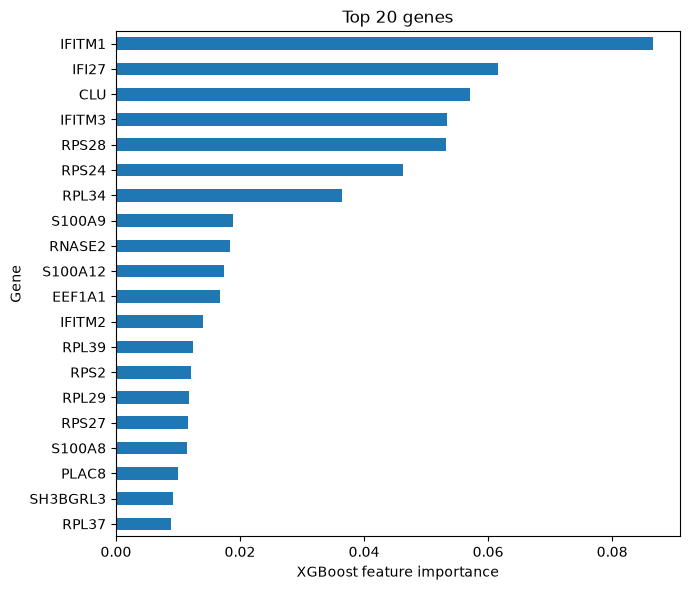

In [19]:
# Get the feature importances and match them to the retained gene names
gene_importance = pd.Series(
    model.named_steps["xgb"].feature_importances_,
    index=selected_genes,
    name="Importance",
).sort_values(ascending=False)

# Visualize the 20 genes with the highest importance
gene_importance.head(20).sort_values().plot.barh(figsize=(7, 6))
plt.xlabel("XGBoost feature importance")
plt.ylabel("Gene")
plt.title("Top 20 genes")
plt.tight_layout()
plt.show()

# Save the Model and Predictions

We save the fitted pipeline with its gene order, label meanings, donor splits, preprocessing,
CV settings, and package versions. New data must use the same genes and expression preprocessing.
The observed normalization scale in this file is approximately 3,351 per cell before `log1p`.
We don't recover raw molecule counts by undoing the log.

We save results under `outputs/covid_newcastle_xgboost` to keep them separate from the random forest and melanoma results.
The full prediction table marks training and test cells. Training predictions aren't evidence
of performance on unseen donors. The saved model remains fitted on training donors only.

In [20]:
# Create the directory for our results
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the fitted pipeline together with the information needed to use it later
# In particular, we need the gene order and preprocessing used for the training data.
model_bundle = {
    "pipeline": model,
    "input_genes": input_genes.tolist(),
    "gene_symbols": adata.var["gene_name"].tolist(),
    "selected_genes": selected_genes.tolist(),
    "labels": {0: "Healthy", 1: "COVID-19"},
    "expression_transform": "log1p(library-size-normalized expression)",
    "observed_normalization_total": float(np.median(normalized_totals)),
    "model_type": "XGBoost",
    "class_weighting": "Balanced sample weights calculated from each fit's training labels",
    "site": "Ncl",
    "cell_type": "CD14-positive monocyte",
    "donor_field": "patient_id",
    "donor_aliases": donor_aliases,
    "train_donors": train_donors,
    "test_donors": test_donors,
    "random_state": RANDOM_STATE,
    "cross_validation": {
        "method": "StratifiedGroupKFold",
        "n_splits": 5,
        "selection_metric": "balanced_accuracy",
        "best_params": best_params,
        "mean_validation_balanced_accuracy": float(best_result["mean_balanced_accuracy"]),
        "validation_donors": fold_summary["Validation donor IDs"].tolist(),
    },
    "parameter_grid": param_grid,
    "dataset": DATA_PATH.name,
    "package_versions": {
        package: version(package)
        for package in [
            "scikit-learn",
            "numpy",
            "pandas",
            "scanpy",
            "anndata",
            "scipy",
            "xgboost",
        ]
    },
}
# Save the model to disk
with (OUTPUT_DIR / "xgboost.pkl").open("wb") as f:
    pickle.dump(model_bundle, f)

# Predict on all selected cells and keep track of which cells were used for training
# We only use test-cell predictions for evaluating performance on unseen donors.
cell_predictions = obs.copy()
cell_predictions["true_label"] = y
cell_predictions["split"] = np.where(
    obs["donor_id"].isin(train_donors), "train", "test"
)
cell_predictions["predicted_label"] = model.predict(X)
cell_predictions["predicted_condition"] = cell_predictions["predicted_label"].map(
    {0: "Healthy", 1: "COVID-19"}
)
cell_predictions["covid_probability"] = model.predict_proba(X)[:, covid_column]

# Save the prediction tables, CV results, metrics and gene importances
cell_predictions.to_csv(OUTPUT_DIR / "cell_predictions.csv", index_label="cell")
test_predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index_label="cell")
cv_results.to_csv(OUTPUT_DIR / "cv_parameter_results.csv")
cv_fold_results.to_csv(OUTPUT_DIR / "cv_all_fold_results.csv", index=False)
cv_fold_metrics.to_csv(OUTPUT_DIR / "cv_fold_metrics.csv")
metrics.to_csv(OUTPUT_DIR / "test_metrics.csv")
donor_metrics.to_csv(OUTPUT_DIR / "test_metrics_by_donor.csv")
gene_importance.to_csv(OUTPUT_DIR / "gene_importance.csv", index_label="gene")
print(f"Saved the model and results to {OUTPUT_DIR.resolve()}")

Saved the model and results to /Users/ioamy269/Documents/GitHub/cellstates/outputs/covid_newcastle_xgboost


# Extra Things We Could Try

- **Model comparison:** compare the preserved random forest version or try logistic regression with the same donor splits and compare the CV scores.
- **Feature selection and learning curves:** compare a smaller training-selected gene set or vary the
  number of training donors to see what helps the model.
- **Nested grouped CV:** evaluate the tuning procedure over multiple outer donor splits.
  Our current test result depends on one split and has few healthy test donors.
- **Donor-level predictions:** average probabilities across cells and evaluate one prediction per donor.
  We could also weight training cells so donors contribute equally.
- **Error inspection:** check whether errors vary with donor, clinical severity, collection day,
  or the two author-defined CD14 monocyte groups.
- **Calibration and thresholds:** use grouped validation if we want better-calibrated probabilities
  or a different trade-off between finding COVID-19 samples and false positives.
- **Another site:** test transfer to a site with both conditions and compatible preprocessing.
  Even within Newcastle, age, sex, sampling, and other donor differences may affect the model.
- **Final training:** once we finish choosing and evaluating the approach, fit a separate model
  on all selected donors for future predictions.